## Project storage — Google Drive connection

This optional first step connects to the original project files saved in Google Drive. A reader can view the saved notebook outputs without connecting to the author’s Drive.

**Step: Connect Google Drive and locate project files.**

In [ ]:
from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount("/content/drive", force_remount=True)

# Permanent project location
project_dir = Path("/content/drive/MyDrive/BDD100K_Project")

# Dataset paths
yaml_path = project_dir / "data.yaml"
manifest_path = project_dir / "val_manifest.json"

print("Google Drive connected!")
print("Project folder exists:", project_dir.exists())
print("Dataset YAML exists:", yaml_path.exists())
print("Validation manifest exists:", manifest_path.exists())

Mounted at /content/drive
Google Drive connected!
Project folder exists: True
Dataset YAML exists: False
Validation manifest exists: False


# Day vs. Night Object Detection — YOLOv8n on BDD100K

**Assignment notebook.** This notebook prepares BDD100K images, evaluates a COCO-pretrained baseline, and fine-tunes models under different lighting conditions. It includes code, saved outputs, and experimental comparisons.

**Structure:** Part A — Setup; Part B — Dataset Preparation; Part C — E0 Baseline; Part D — E1 Balanced; Part E — E2 Night-only; Part F — E4 Day-only. **E4 in the notebook corresponds to E3 in the written report.**

**Classes:** person, bicycle, car, bus, truck. **Validation:** 750 daytime and 750 nighttime images.

**Execution note:** The notebook contains both Google Colab Drive paths and local Jupyter paths. Review paths before rerunning in a different environment. Saved notebook outputs can be inspected without rerunning.


## Part A — Environment and YOLOv8 demonstration

Set up dependencies, check the available compute device, and inspect an example pretrained prediction.

### A1 — Install required packages

**Step: Install project dependencies.**

In [ ]:
# Run once in the Jupyter environment, then restart the kernel if requested.
%pip install ultralytics kagglehub pillow pyyaml opencv-python matplotlib pandas


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 7.7 MB/s eta 0:00:00


### A2 — Inspect Python and GPU environment

**Step: Check runtime and GPU availability.**

In [ ]:
import torch
from ultralytics import YOLO
from pathlib import Path


print("CUDA available:", torch.cuda.is_available())
print("Working directory:", Path.cwd())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
CUDA available: False
Working directory: /content


### A3 — Demonstrate pretrained object detection

**Step: Run a pretrained YOLOv8 demonstration.**


image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 485.7ms
Speed: 88.6ms preprocess, 485.7ms inference, 52.3ms postprocess per image at shape (1, 3, 640, 480)


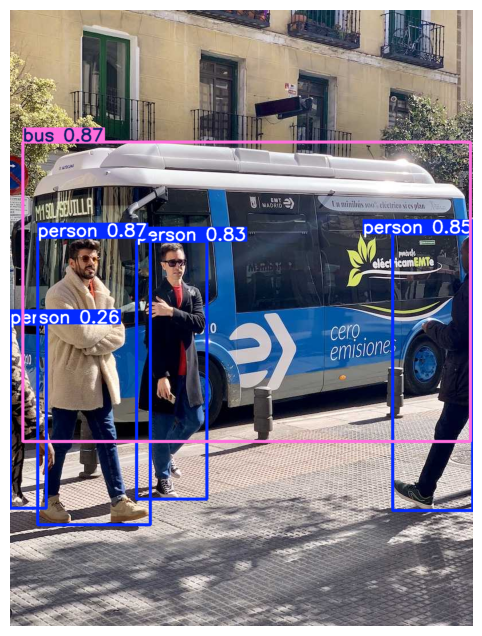

In [ ]:
import sys
import subprocess

try:
    from ultralytics import YOLO
except ModuleNotFoundError:
    print("Installing ultralytics in the active environment...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ultralytics"])
    from ultralytics import YOLO

import cv2
import matplotlib.pyplot as plt

# Load pre-trained YOLOv8
model = YOLO("yolov8n.pt")

# Detect only person, bicycle, car, bus and truck
results = model.predict(
    source="https://ultralytics.com/images/bus.jpg",
    conf=0.25,
    classes=[0, 1, 2, 5, 7]
)

# Draw bounding boxes
annotated_image = results[0].plot()

# Display image
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

**Step: Inspect predicted object classes and confidence scores.**

In [ ]:
for box in results[0].boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    print(
        f"Object: {model.names[class_id]}, "
        f"Confidence: {confidence:.2f}"
    )

Object: bus, Confidence: 0.87
Object: person, Confidence: 0.87
Object: person, Confidence: 0.85
Object: person, Confidence: 0.83
Object: person, Confidence: 0.26


## Part B — BDD100K Dataset Preparation

Prepare the five-class BDD100K dataset and its training, validation, and test folders. The reported experiment comparisons in this notebook use the **validation** split; the prepared test split is not used for those comparisons.

### B1 — Import data processing tools

**Step: Import dataset-processing libraries.**

In [ ]:
import json, random, shutil
from pathlib import Path
from collections import Counter
from PIL import Image
import yaml
import cv2
import matplotlib.pyplot as plt

**Step: Verify Python environment and dependencies.**

In [ ]:
import sys
import subprocess

print("Python executable:", sys.executable)
print("Python version:", sys.version)

subprocess.run([
    sys.executable, "-m", "pip", "show",
    "numpy", "opencv-python", "matplotlib"
])

Python executable: /usr/bin/python3
Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'show', 'numpy', 'opencv-python', 'matplotlib'], returncode=0)

### B2 — Locate the BDD100K dataset

**Step: Locate or download the BDD100K dataset.**

In [ ]:
import kagglehub
from pathlib import Path

# Set this to your existing Kaggle BDD100K dataset root to avoid re-downloading.
# Example: EXISTING_DATASET_DIR = Path(r"D:/datasets/solesensei_bdd100k")
EXISTING_DATASET_DIR = None

if EXISTING_DATASET_DIR is not None:
    dataset_dir = Path(EXISTING_DATASET_DIR).expanduser().resolve()
else:
    dataset_dir = Path(kagglehub.dataset_download("solesensei/solesensei_bdd100k")).resolve()

assert dataset_dir.is_dir(), f"Dataset folder does not exist: {dataset_dir}"
print("Dataset:", dataset_dir)


Using Colab cache for faster access to the 'solesensei_bdd100k' dataset.
Dataset: /kaggle/input/solesensei_bdd100k


### B3 — Read official annotations

**Step: Load training and validation annotations.**

In [ ]:

import json
from pathlib import Path
import time

start = time.time()

# Direct path to the annotation folder
labels_dir = dataset_dir / "bdd100k_labels_release" / "bdd100k" / "labels"

train_json = labels_dir / "bdd100k_labels_images_train.json"
val_json = labels_dir / "bdd100k_labels_images_val.json"

# Check that the files exist
print("Training JSON exists:", train_json.exists())
print("Validation JSON exists:", val_json.exists())

assert train_json.is_file(), f"File not found: {train_json}"
assert val_json.is_file(), f"File not found: {val_json}"

# Load training annotations
print("Loading training annotations...")
with open(train_json, "r", encoding="utf-8") as f:
    annotations = json.load(f)

# Load validation annotations
print("Loading validation annotations...")
with open(val_json, "r", encoding="utf-8") as f:
    val_annotations = json.load(f)

print("Training records:", len(annotations))
print("Validation records:", len(val_annotations))
print("Time taken:", round(time.time() - start, 2), "seconds")


Training JSON exists: True
Validation JSON exists: True
Loading training annotations...
Loading validation annotations...
Training records: 69863
Validation records: 10000
Time taken: 51.93 seconds


### B4 — Inspect lighting-condition distribution

**Step: Count images by lighting condition.**

In [ ]:
for name, records in [("Official train", annotations), ("Official validation", val_annotations)]:
    print(name, Counter(x.get("attributes", {}).get("timeofday") for x in records))

Official train Counter({'daytime': 36728, 'night': 27971, 'dawn/dusk': 5027, 'undefined': 137})
Official validation Counter({'daytime': 5258, 'night': 3929, 'dawn/dusk': 778, 'undefined': 35})


### B5 — Select reproducible dataset subsets

The original balanced training subset contains 3,500 daytime and 3,500 nighttime images. The validation subset contains 750 images per lighting condition.

**Step: Sample daytime and nighttime subsets.**

In [ ]:
import random

rng = random.Random(42)

# Separate daytime and nighttime images from training annotations
day_images = [
    img for img in annotations
    if img.get("attributes", {}).get("timeofday") == "daytime"
]

night_images = [
    img for img in annotations
    if img.get("attributes", {}).get("timeofday") == "night"
]

# Separate daytime and nighttime images from validation annotations
val_day_images = [
    img for img in val_annotations
    if img.get("attributes", {}).get("timeofday") == "daytime"
]

val_night_images = [
    img for img in val_annotations
    if img.get("attributes", {}).get("timeofday") == "night"
]

# Select 7000 training images
train_day = rng.sample(day_images, 3500)
train_night = rng.sample(night_images, 3500)

train_data = train_day + train_night

# Select 3000 images for validation and testing
selected_val_day = rng.sample(val_day_images, 1500)
selected_val_night = rng.sample(val_night_images, 1500)

# Create validation dataset
val_data = selected_val_day[:750] + selected_val_night[:750]

# Create testing dataset
test_data = selected_val_day[750:] + selected_val_night[750:]

# Shuffle datasets
rng.shuffle(train_data)
rng.shuffle(val_data)
rng.shuffle(test_data)

# Check dataset sizes
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))
print("Total images:", len(train_data) + len(val_data) + len(test_data))

Training images: 7000
Validation images: 1500
Testing images: 1500
Total images: 10000


### B6 — Check split separation

**Step: Check overlap between dataset splits.**

In [ ]:
train_names = {img["name"] for img in train_data}
val_names = {img["name"] for img in val_data}
test_names = {img["name"] for img in test_data}

print("Train/Validation overlap:", len(train_names & val_names))
print("Train/Test overlap:", len(train_names & test_names))
print("Validation/Test overlap:", len(val_names & test_names))

assert len(train_names & val_names) == 0
assert len(train_names & test_names) == 0
assert len(val_names & test_names) == 0

print("All splits are separate!")

Train/Validation overlap: 0
Train/Test overlap: 0
Validation/Test overlap: 0
All splits are separate!


### B7 — Find source images

**Step: Index the source image files.**

In [ ]:
from pathlib import Path

image_root = Path(dataset_dir) / "bdd100k/bdd100k/images/100k"

train_image_dir = image_root / "train"
val_image_dir = image_root / "val"

assert train_image_dir.is_dir(), f"Training folder missing: {train_image_dir}"
assert val_image_dir.is_dir(), f"Validation folder missing: {val_image_dir}"

def build_lookup(root):
    lookup = {}

    # Search only within the actual image directory,
    # not the entire Kaggle dataset.
    for path in root.rglob("*.jpg"):
        if path.name in lookup:
            raise ValueError(f"Duplicate filename: {path.name}")
        lookup[path.name] = path

    return lookup

train_image_lookup = build_lookup(train_image_dir)
val_image_lookup = build_lookup(val_image_dir)

print("Training images indexed:", len(train_image_lookup))
print("Validation images indexed:", len(val_image_lookup))

Training images indexed: 70000
Validation images indexed: 10000


### B8 — Verify image availability

**Step: Check that selected images exist.**

In [ ]:
# Check training images
missing_train = [
    img["name"] for img in train_data
    if img["name"] not in train_image_lookup
]

# Check validation images
missing_val = [
    img["name"] for img in val_data
    if img["name"] not in val_image_lookup
]

# Check testing images
missing_test = [
    img["name"] for img in test_data
    if img["name"] not in val_image_lookup
]

print("Missing training images:", len(missing_train))
print("Missing validation images:", len(missing_val))
print("Missing testing images:", len(missing_test))

assert not missing_train
assert not missing_val
assert not missing_test

print("All 10,000 selected images found!")

Missing training images: 0
Missing validation images: 0
Missing testing images: 0
All 10,000 selected images found!


### B9 — Assemble project image folders

**Step: Copy selected images into project folders.**

In [ ]:
import shutil
from pathlib import Path

# Set PROJECT_DIR to a permanent folder on your computer if desired.
PROJECT_DIR = Path.cwd() / "BDD100K_Project"
project_dir = PROJECT_DIR.expanduser().resolve()
splits = {
    "train": (train_data, train_image_lookup),
    "val": (val_data, val_image_lookup),
    "test": (test_data, val_image_lookup),
}
for split, (records, lookup) in splits.items():
    image_output = project_dir / "images" / split
    label_output = project_dir / "labels" / split
    image_output.mkdir(parents=True, exist_ok=True)
    label_output.mkdir(parents=True, exist_ok=True)
    expected_names = {record["name"] for record in records}
    # Remove stale images and labels from previous selections.
    for old in image_output.glob("*.jpg"):
        if old.name not in expected_names:
            old.unlink()
    expected_stems = {Path(name).stem for name in expected_names}
    for old in label_output.glob("*.txt"):
        if old.stem not in expected_stems:
            old.unlink()
    for record in records:
        source = lookup[record["name"]]
        destination = image_output / record["name"]
        if not destination.exists() or destination.stat().st_size != source.stat().st_size:
            shutil.copy2(source, destination)
    count = len(list(image_output.glob("*.jpg")))
    assert count == len(records), f"{split}: expected {len(records)}, found {count}"
    print(f"{split}: {count} images ready")


train: 7000 images ready
val: 1500 images ready
test: 1500 images ready


### B10 — Define target classes

**Step: Define the five detection categories.**

In [ ]:
class_mapping = {
    "person": 0,
    "bike": 1,
    "car": 2,
    "bus": 3,
    "truck": 4
}

print(class_mapping)

{'person': 0, 'bike': 1, 'car': 2, 'bus': 3, 'truck': 4}


### B11 — Convert bounding-box annotations

**Step: Convert BDD100K boxes to YOLO labels.**

In [ ]:
from PIL import Image
from pathlib import Path

def convert_to_yolo(records, split):
    image_dir = project_dir / "images" / split
    label_dir = project_dir / "labels" / split

    label_dir.mkdir(parents=True, exist_ok=True)

    converted = 0
    total_boxes = 0

    for record in records:
        image_name = record["name"]
        image_path = image_dir / image_name
        label_path = label_dir / (Path(image_name).stem + ".txt")

        # Get actual image dimensions
        with Image.open(image_path) as image:
            img_width, img_height = image.size

        yolo_labels = []

        for obj in record.get("labels", []):
            category = obj.get("category")

            # Keep only our five classes
            if category not in class_mapping:
                continue

            # Skip objects without bounding boxes
            box = obj.get("box2d")

            if not box:
                continue

            x1 = max(0, min(float(box["x1"]), img_width))
            y1 = max(0, min(float(box["y1"]), img_height))
            x2 = max(0, min(float(box["x2"]), img_width))
            y2 = max(0, min(float(box["y2"]), img_height))

            # Skip invalid boxes
            if x2 <= x1 or y2 <= y1:
                continue

            # Convert to normalized YOLO coordinates
            x_center = ((x1 + x2) / 2) / img_width
            y_center = ((y1 + y2) / 2) / img_height

            width = (x2 - x1) / img_width
            height = (y2 - y1) / img_height

            class_id = class_mapping[category]

            yolo_labels.append(
                f"{class_id} {x_center:.6f} {y_center:.6f} "
                f"{width:.6f} {height:.6f}"
            )

        # Create a label file even when no target objects exist
        label_path.write_text("\n".join(yolo_labels))

        converted += 1
        total_boxes += len(yolo_labels)

    print(f"{split}: {converted} images converted")
    print(f"{split}: {total_boxes} bounding boxes")


# Convert all three datasets
convert_to_yolo(train_data, "train")
convert_to_yolo(val_data, "val")
convert_to_yolo(test_data, "test")

train: 7000 images converted
train: 83832 bounding boxes
val: 1500 images converted
val: 18075 bounding boxes
test: 1500 images converted
test: 17748 bounding boxes


### B12 — Write dataset configuration

**Step: Create the YOLO dataset YAML.**

In [ ]:
import yaml

data_config = {
    "path": str(project_dir),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 5,
    "names": {
        0: "person",
        1: "bicycle",
        2: "car",
        3: "bus",
        4: "truck"
    }
}

yaml_path = project_dir / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("Created:", yaml_path)

with open(yaml_path) as f:
    print(f.read())

Created: /content/BDD100K_Project/data.yaml
path: /content/BDD100K_Project
train: images/train
val: images/val
test: images/test
nc: 5
names:
  0: person
  1: bicycle
  2: car
  3: bus
  4: truck



### B13 — Verify dataset structure

**Step: Verify image and label counts.**

In [ ]:
for split, expected in [("train", 7000), ("val", 1500), ("test", 1500)]:
    image_dir = project_dir / "images" / split
    label_dir = project_dir / "labels" / split
    images = list(image_dir.glob("*.jpg"))
    labels = list(label_dir.glob("*.txt"))
    missing = [p.name for p in images if not (label_dir / f"{p.stem}.txt").is_file()]
    assert len(images) == expected, f"{split}: expected {expected} images, got {len(images)}"
    assert len(labels) == expected, f"{split}: expected {expected} labels, got {len(labels)}"
    assert not missing, f"{split}: missing labels: {missing[:5]}"
    for label in labels:
        for line in label.read_text().splitlines():
            fields = line.split()
            assert len(fields) == 5, f"Malformed annotation in {label}: {line}"
            class_id = int(fields[0])
            coords = [float(v) for v in fields[1:]]
            assert class_id in range(5), (label, class_id)
            assert all(0 <= v <= 1 for v in coords), (label, coords)
            assert coords[2] > 0 and coords[3] > 0, (label, coords)
    print(f"{split}: {expected} image/label pairs and YOLO coordinates verified")


train: 7000 image/label pairs and YOLO coordinates verified
val: 1500 image/label pairs and YOLO coordinates verified
test: 1500 image/label pairs and YOLO coordinates verified


### B14 — Inspect example annotations

**Step: Visualize a labeled example.**

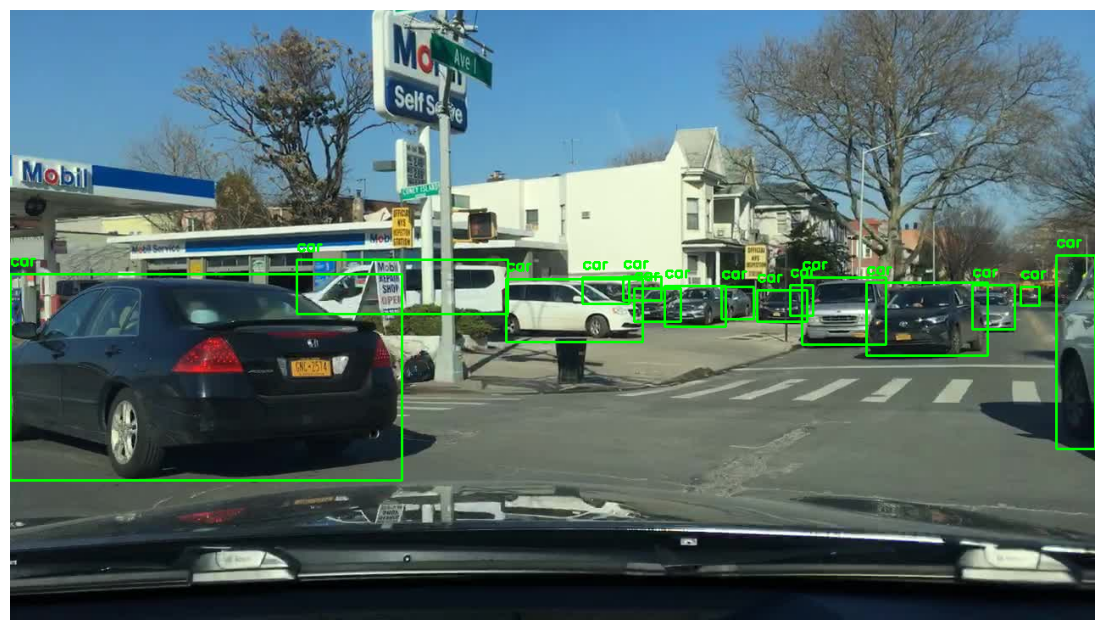

In [ ]:
import cv2
import matplotlib.pyplot as plt
import random

# Our five classes
class_names = ["person", "bicycle", "car", "bus", "truck"]

# Select a random training image
image_dir = project_dir / "images" / "train"
label_dir = project_dir / "labels" / "train"

image_path = random.choice(list(image_dir.glob("*.jpg")))
label_path = label_dir / (image_path.stem + ".txt")

# Read the image
image = cv2.imread(str(image_path))
height, width = image.shape[:2]

# Read the YOLO annotation
with open(label_path, "r") as f:
    labels = f.readlines()

# Draw bounding boxes
for label in labels:
    values = label.strip().split()

    class_id = int(values[0])
    x_center, y_center, w, h = map(float, values[1:])

    # Convert normalized coordinates to pixels
    x1 = int((x_center - w / 2) * width)
    y1 = int((y_center - h / 2) * height)
    x2 = int((x_center + w / 2) * width)
    y2 = int((y_center + h / 2) * height)

    # Draw bounding box
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

    # Display object category
    cv2.putText(
        image,
        class_names[class_id],
        (x1, max(y1 - 10, 15)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

# Display image
plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

### B15 — Record split

**Step: Save dataset split manifests.**

In [ ]:
for split, records in [("train", train_data), ("val", val_data), ("test", test_data)]:
    manifest = [{"name": x["name"], "timeofday": x.get("attributes", {}).get("timeofday")} for x in records]
    with open(project_dir / f"{split}_manifest.json", "w") as f:
        json.dump(manifest, f, indent=2)
    print(split, len(manifest))

train 7000
val 1500
test 1500


## Part C — Experiment E0: COCO-pretrained baseline

Evaluate pretrained YOLOv8n **without BDD100K fine-tuning** on daytime and nighttime validation images. For E0, the five target classes are mapped to their COCO class IDs.

### C1 — Prepare E0 evaluation inputs

**Step: Load validation manifest and baseline settings.**

In [ ]:
import json, shutil, os
from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import matplotlib.pyplot as plt

project_dir = PROJECT_DIR.expanduser().resolve()
assert (project_dir / "data.yaml").is_file(), "Run Part B first: data.yaml missing"
assert (project_dir / "val_manifest.json").is_file(), "Run Part B first: val_manifest.json missing"
with open(project_dir / "val_manifest.json", encoding="utf-8") as f:
    val_manifest = json.load(f)
assert len(val_manifest) == 1500, f"Expected 1500 validation images, found {len(val_manifest)}"
from collections import Counter
counts = Counter(x["timeofday"] for x in val_manifest)
assert counts["daytime"] == counts["night"] == 750, counts
print("Validation day/night:", counts)

Validation day/night: Counter({'night': 750, 'daytime': 750})


### C2 — Map labels into COCO class indices

**Step: Map BDD100K labels to COCO IDs.**

In [ ]:
import yaml

# Five-class BDD100K IDs -> original COCO IDs
custom_to_coco = {0: 0, 1: 1, 2: 2, 3: 5, 4: 7}
e0_root = project_dir / "E0_COCO_Evaluation"
model_e0 = YOLO("yolov8n.pt")
assert len(model_e0.names) == 80

for condition in ["daytime", "night"]:
    subset = "day" if condition == "daytime" else "night"
    img_out = e0_root / "images" / subset
    lbl_out = e0_root / "labels" / subset
    img_out.mkdir(parents=True, exist_ok=True)
    lbl_out.mkdir(parents=True, exist_ok=True)
    records = [r for r in val_manifest if r["timeofday"] == condition]
    for rec in records:
        name = rec["name"]
        src_img = project_dir / "images" / "val" / name
        src_lbl = project_dir / "labels" / "val" / (Path(name).stem + ".txt")
        dst_img = img_out / name
        dst_lbl = lbl_out / (Path(name).stem + ".txt")
        assert src_img.is_file() and src_lbl.is_file(), f"Missing source: {name}"
        if not dst_img.exists():
            try:
                os.link(src_img, dst_img)
            except OSError:
                shutil.copy2(src_img, dst_img)
        converted = []
        for line in src_lbl.read_text().splitlines():
            parts = line.split()
            if not parts:
                continue
            old_id = int(parts[0])
            assert old_id in custom_to_coco, (name, old_id)
            converted.append(" ".join([str(custom_to_coco[old_id])] + parts[1:]))
        dst_lbl.write_text("\n".join(converted), encoding="utf-8")
    print(subset, len(records), "images prepared")

coco_names = {int(k): v for k, v in model_e0.names.items()}
e0_yaml = e0_root / "e0_data.yaml"
with open(e0_yaml, "w", encoding="utf-8") as f:
    yaml.safe_dump({"path": str(e0_root.resolve()), "train": "images/day", "val": "images/day", "test": "images/night", "nc": 80, "names": coco_names}, f, sort_keys=False)
print("E0 dataset config:", e0_yaml)

day 750 images prepared
night 750 images prepared
E0 dataset config: /content/BDD100K_Project/E0_COCO_Evaluation/e0_data.yaml


### C3 — Evaluate the baseline model

**Step: Evaluate pretrained model on day and night.**

In [ ]:
# Explicitly limit evaluation to five target classes; the 80-class YAML keeps class IDs valid.
TARGET_COCO_IDS = [0, 1, 2, 5, 7]
results_e0 = {}
for condition, subset in [("daytime", "day"), ("nighttime", "night")]:
    print("\nEvaluating:", condition)
    # Pass dataset split by selecting YAML val (day) or test (night).
    split = "val" if subset == "day" else "test"
    metrics = model_e0.val(
        data=str(e0_yaml), split=split, classes=TARGET_COCO_IDS,
        imgsz=640, batch=8, device=0 if torch.cuda.is_available() else "cpu",
        plots=False, project=str(project_dir / "experiment_results"),
        name=f"E0_{subset}", exist_ok=True, verbose=False,
    )
    results_e0[condition] = metrics
    print(f"{condition}: mAP50={metrics.box.map50:.4f}, mAP50-95={metrics.box.map:.4f}, "
          f"precision={metrics.box.mp:.4f}, recall={metrics.box.mr:.4f}")


Evaluating: daytime
Ultralytics 8.4.183 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1812.3±573.7 MB/s, size: 68.4 KB)
val: Scanning /content/BDD100K_Project/E0_COCO_Evaluation/labels/day... 750 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 750/750 1.7Kit/s 0.5s
val: New cache created: /content/BDD100K_Project/E0_COCO_Evaluation/labels/day.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 94/94 1.3s/it 2:03
                   all        750      10305      0.526      0.309      0.335      0.204
Speed: 3.6ms preprocess, 148.2ms inference, 0.0ms loss, 2.5ms postprocess per image
daytime: mAP50=0.3353, mAP50-95=0.2045, precision=0.5261, recall=0.3086

Evaluating: nighttime
Ultralytics 8.4.183 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n summa

### C4 — Compare E0 metrics

**Step: Summarize baseline metrics and plots.**

              day   night     gap
mAP50      0.3353  0.2448  0.0904
mAP50-95   0.2045  0.1427  0.0618
precision  0.5261  0.3810  0.1451
recall     0.3086  0.2631  0.0454


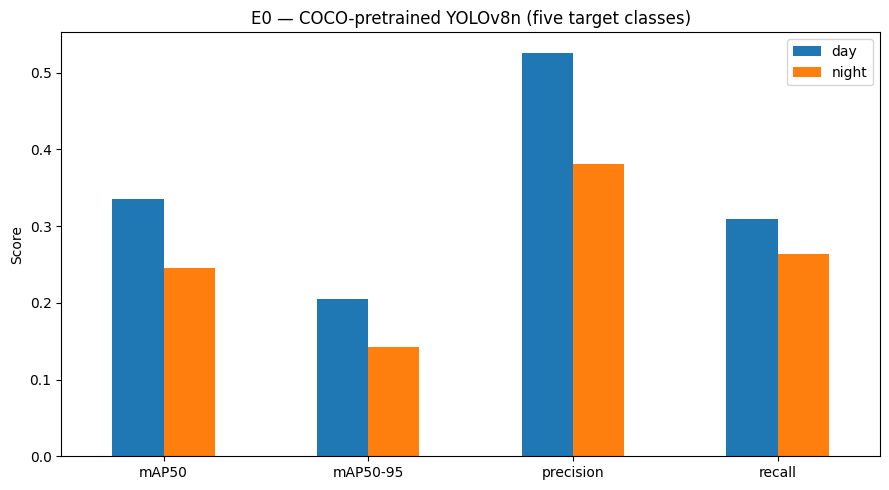

Saved results to: /content/BDD100K_Project/experiment_results


In [ ]:
metric_values = {
    "mAP50": lambda m: m.box.map50,
    "mAP50-95": lambda m: m.box.map,
    "precision": lambda m: m.box.mp,
    "recall": lambda m: m.box.mr,
}
comparison = pd.DataFrame({
    "day": {k: fn(results_e0["daytime"]) for k, fn in metric_values.items()},
    "night": {k: fn(results_e0["nighttime"]) for k, fn in metric_values.items()},
})
comparison["gap"] = comparison["day"] - comparison["night"]
print(comparison.round(4))
result_dir = project_dir / "experiment_results"
result_dir.mkdir(exist_ok=True)
comparison.to_csv(result_dir / "E0_day_night_metrics.csv")
ax = comparison[["day", "night"]].plot.bar(figsize=(9, 5), rot=0)
ax.set_ylabel("Score")
ax.set_title("E0 — COCO-pretrained YOLOv8n (five target classes)")
plt.tight_layout()
plt.savefig(result_dir / "E0_day_night_comparison.png", dpi=160)
plt.show()
print("Saved results to:", result_dir)

### C5 — Inspect per-class baseline results

**Step: Inspect per-class baseline AP.**

In [ ]:
class_ids = [0, 1, 2, 5, 7]
class_labels = ["person", "bicycle", "car", "bus", "truck"]
per_class = {}
for condition in ["daytime", "nighttime"]:
    metric = results_e0[condition]
    # ap50 is aligned to metric.box.ap_class_index, not to all 80 classes.
    scores = dict(zip([int(i) for i in metric.box.ap_class_index], metric.box.ap50))
    per_class[condition] = {label: scores.get(idx, float("nan")) for idx, label in zip(class_ids, class_labels)}
class_table = pd.DataFrame(per_class)
print(class_table.round(4))
class_table.to_csv(result_dir / "E0_per_class_AP50.csv")

         daytime  nighttime
person    0.4027     0.2560
bicycle   0.2049     0.1085
car       0.5352     0.3802
bus       0.3102     0.3044
truck     0.2233     0.1750


## Part D — Experiment E1: Balanced fine-tuning


### D1 — E1 training and evaluation workflow

**Step: Locate the prepared training dataset.**

In [ ]:
from pathlib import Path

# Redefine the project paths in case the kernel was restarted
project_dir = Path.cwd() / "BDD100K_Project"
yaml_path = project_dir / "data.yaml"

assert yaml_path.is_file(), "Dataset YAML not found"
print("Using dataset:", yaml_path)

Using dataset: /content/BDD100K_Project/data.yaml


**Step: Fine-tune E1 on balanced training images.**

In [ ]:
from ultralytics import YOLO
import torch

device = 0 if torch.cuda.is_available() else "cpu"

model_e1 = YOLO("yolov8n.pt")

results_e1 = model_e1.train(
    data=str(yaml_path),
    epochs=20,
    imgsz=640,
    batch=8,
    device=device,
    workers=0,
    project=str(project_dir / "experiment_results"),
    name="E1_Balanced_Training",
    seed=42,
    plots=True
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/BDD100K_Project/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=E1_Balanced_Training, nbs=64, nms=None, opset=None, opt

**Step: Load E1 best checkpoint and training plot.**

Loaded: /content/BDD100K_Project/experiment_results/E1_Balanced_Training/weights/best.pt


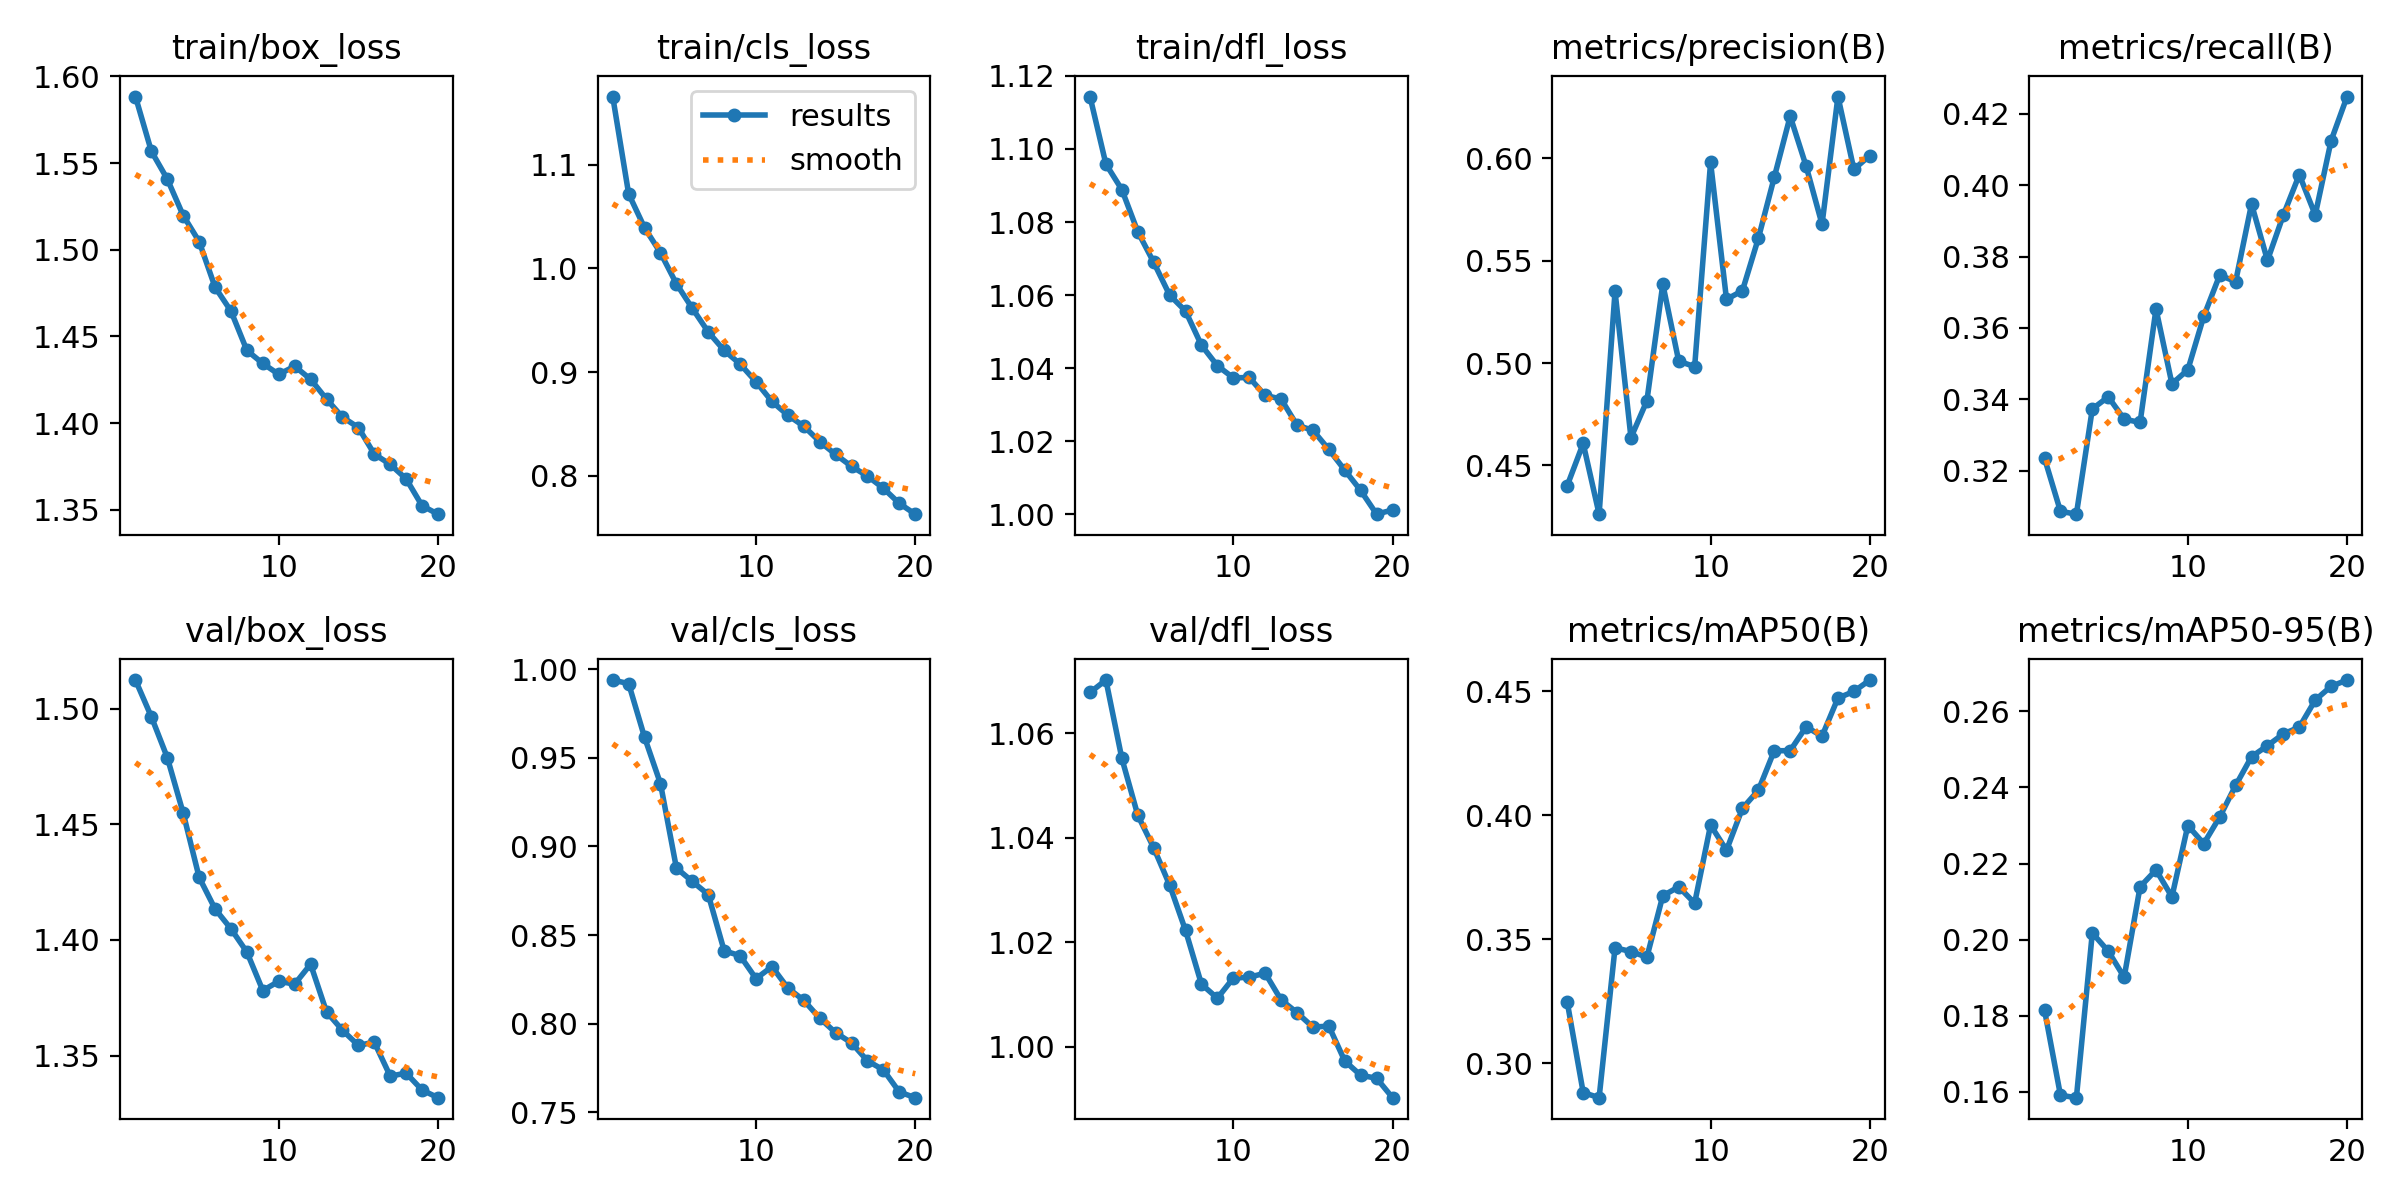

In [ ]:
training_dir = project_dir / "experiment_results" / "E1_Balanced_Training"
best_path = training_dir / "weights" / "best.pt"
assert best_path.is_file(), f"Missing best checkpoint: {best_path}"
best_e1 = YOLO(str(best_path))
print("Loaded:", best_path)
results_plot = training_dir / "results.png"
if results_plot.is_file():
    from IPython.display import display, Image
    display(Image(filename=str(results_plot)))
else:
    print("Training plot not found; check:", training_dir)

**Step: Save E1 checkpoints to Google Drive.**

In [ ]:
from pathlib import Path
import shutil

# Locate the actual E1 training run
run_dir = Path(model_e1.trainer.save_dir)

best_model = run_dir / "weights" / "best.pt"
last_model = run_dir / "weights" / "last.pt"

# Permanent storage
drive_save_dir = Path(
    "/content/drive/MyDrive/BDD100K_Project/saved_models/E1"
)
drive_save_dir.mkdir(parents=True, exist_ok=True)

assert best_model.is_file(), f"Missing model: {best_model}"

shutil.copy2(best_model, drive_save_dir / "best.pt")

if last_model.is_file():
    shutil.copy2(last_model, drive_save_dir / "last.pt")

print("E1 model saved successfully!")
print("Location:", drive_save_dir)

E1 model saved successfully!
Location: /content/drive/MyDrive/BDD100K_Project/saved_models/E1


**Step: Load E1 model and validation metadata.**

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import json
import yaml

# Existing project paths
project_dir = Path(project_dir)
yaml_path = project_dir / "data.yaml"
manifest_path = project_dir / "val_manifest.json"

# Load E1 best checkpoint
if "model_e1" in globals() and hasattr(model_e1, "trainer") and model_e1.trainer:
    best_pt = Path(model_e1.trainer.save_dir) / "weights" / "best.pt"
else:
    best_pt = (
        Path("/content/drive/MyDrive/BDD100K_Project")
        / "saved_models/E1/best.pt"
    )

assert best_pt.is_file(), f"Model checkpoint not found: {best_pt}"
assert yaml_path.is_file(), f"Dataset configuration not found: {yaml_path}"
assert manifest_path.is_file(), f"Manifest not found: {manifest_path}"

model = YOLO(str(best_pt))

with open(yaml_path) as f:
    config = yaml.safe_load(f)

with open(manifest_path) as f:
    manifest = json.load(f)

print("Model:", best_pt)
print("Manifest type:", type(manifest).__name__)
print("First manifest entry:", manifest[0] if isinstance(manifest, list) else list(manifest.items())[:1])

Model: /content/BDD100K_Project/experiment_results/E1_Balanced_Training/weights/best.pt
Manifest type: list
First manifest entry: {'name': 'bdd5b47b-d9ea627b.jpg', 'timeofday': 'night'}


**Step: Prepare separate day and night evaluation lists.**

In [ ]:
from pathlib import Path
import pandas as pd
import yaml

# Use the model, config, and manifest loaded in the previous cell
project_dir = Path(project_dir)

# Separate validation images by time of day
day_names = [
    item["name"] for item in manifest
    if item["timeofday"] == "daytime"
]

night_names = [
    item["name"] for item in manifest
    if item["timeofday"] == "night"
]

print("Daytime images:", len(day_names))
print("Nighttime images:", len(night_names))

assert len(day_names) == 750, "Expected 750 daytime images"
assert len(night_names) == 750, "Expected 750 nighttime images"

# Create separate image lists for Ultralytics
eval_dir = project_dir / "evaluation_splits"
eval_dir.mkdir(parents=True, exist_ok=True)

val_image_dir = project_dir / "images" / "val"

def create_image_list(names, filename):
    paths = [val_image_dir / name for name in names]

    missing = [str(p) for p in paths if not p.is_file()]
    assert not missing, f"Missing images: {missing[:5]}"

    output = eval_dir / filename

    with open(output, "w") as f:
        for path in paths:
            f.write(str(path.resolve()) + "\n")

    return output

day_list = create_image_list(day_names, "day_images.txt")
night_list = create_image_list(night_names, "night_images.txt")

# Create YAML configurations for each evaluation split
with open(yaml_path) as f:
    base_config = yaml.safe_load(f)

def create_eval_yaml(image_list, filename):
    config = base_config.copy()
    config["path"] = str(project_dir.resolve())
    config["val"] = str(image_list.resolve())

    output = eval_dir / filename

    with open(output, "w") as f:
        yaml.safe_dump(config, f, sort_keys=False)

    return output

day_yaml = create_eval_yaml(day_list, "day.yaml")
night_yaml = create_eval_yaml(night_list, "night.yaml")

print("Day YAML:", day_yaml)
print("Night YAML:", night_yaml)

Daytime images: 750
Nighttime images: 750
Day YAML: /content/BDD100K_Project/evaluation_splits/day.yaml
Night YAML: /content/BDD100K_Project/evaluation_splits/night.yaml


**Step: Evaluate E1 on both lighting conditions.**

In [ ]:
# Evaluate trained E1 model on daytime images
day_results = model.val(
    data=str(day_yaml),
    imgsz=640,
    batch=8,
    device=device,
    workers=0,
    plots=False,
    verbose=False
)

# Evaluate the same model on nighttime images
night_results = model.val(
    data=str(night_yaml),
    imgsz=640,
    batch=8,
    device=device,
    workers=0,
    plots=False,
    verbose=False
)

print("Daytime and nighttime evaluations completed!")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2187.8±465.9 MB/s, size: 62.0 KB)
val: Scanning /content/BDD100K_Project/labels/val... 750 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 750/750 2.0Kit/s 0.4s
val: New cache created: /content/BDD100K_Project/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 94/94 9.9it/s 9.5s
                   all        750      10305      0.591      0.426      0.452       0.27
Speed: 0.2ms preprocess, 4.2ms inference, 0.0ms loss, 1.0ms postprocess per image
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1401.7±586.2 MB/s, size: 38.9 KB)
val: Scan

**Step: Compare E1 evaluation metrics.**

In [ ]:
day_metrics = {
    "mAP50": day_results.box.map50,
    "mAP50-95": day_results.box.map,
    "precision": day_results.box.mp,
    "recall": day_results.box.mr
}

night_metrics = {
    "mAP50": night_results.box.map50,
    "mAP50-95": night_results.box.map,
    "precision": night_results.box.mp,
    "recall": night_results.box.mr
}

comparison_e1 = pd.DataFrame({
    "day": day_metrics,
    "night": night_metrics
})

comparison_e1["gap"] = comparison_e1["day"] - comparison_e1["night"]

print("\nE1 — Balanced Training: Day vs Night")
print(comparison_e1.round(4))


E1 — Balanced Training: Day vs Night
              day   night     gap
mAP50      0.4523  0.4791 -0.0267
mAP50-95   0.2704  0.2834 -0.0130
precision  0.5905  0.6524 -0.0619
recall     0.4261  0.4366 -0.0104


### D6 — Inspect validation class distribution

**Step: Count ground-truth objects by class.**

In [ ]:
from collections import Counter
from pathlib import Path

class_names = ["person", "bicycle", "car", "bus", "truck"]

def count_objects(image_names):
    counts = Counter()

    for name in image_names:
        label_file = (
            Path(project_dir) / "labels" / "val"
            / f"{Path(name).stem}.txt"
        )

        if not label_file.exists():
            continue

        for line in label_file.read_text().splitlines():
            if line.strip():
                class_id = int(line.split()[0])
                counts[class_names[class_id]] += 1

    return counts

day_counts = count_objects(day_names)
night_counts = count_objects(night_names)

import pandas as pd

class_comparison = pd.DataFrame({
    "day": day_counts,
    "night": night_counts
}).fillna(0).astype(int)

print(class_comparison)

          day  night
car      8385   6970
bus       155     57
truck     422    127
person   1249    593
bicycle    94     23


**Step: Compare per-class detection accuracy.**

In [ ]:
import pandas as pd

class_names = ["person", "bicycle", "car", "bus", "truck"]

day_ap = day_results.box.maps
night_ap = night_results.box.maps

per_class = pd.DataFrame({
    "class": class_names,
    "day_mAP50_95": day_ap,
    "night_mAP50_95": night_ap
})

per_class["gap"] = (
    per_class["day_mAP50_95"]
    - per_class["night_mAP50_95"]
)

print(per_class.round(4).to_string(index=False))

  class  day_mAP50_95  night_mAP50_95     gap
 person        0.2057          0.1715  0.0342
bicycle        0.1342          0.1932 -0.0589
    car        0.4154          0.3718  0.0436
    bus        0.3233          0.3549 -0.0316
  truck        0.2734          0.3258 -0.0523


**Step: Copy E1 checkpoint to Drive (additional save step).**

In [ ]:
from pathlib import Path
import shutil

e1_best = Path(
    "/content/BDD100K_Project/experiment_results/"
    "E1_Balanced_Training/weights/best.pt"
)

drive_dir = Path(
    "/content/drive/MyDrive/BDD100K_Project"
)

assert e1_best.is_file(), "E1 checkpoint not found"

save_dir = drive_dir / "saved_models/E1"
save_dir.mkdir(parents=True, exist_ok=True)

shutil.copy2(e1_best, save_dir / "best.pt")

print("E1 saved to Google Drive:", save_dir / "best.pt")

E1 saved to Google Drive: /content/drive/MyDrive/BDD100K_Project/saved_models/E1/best.pt


**Step: Visualize E1 predictions on validation images.**

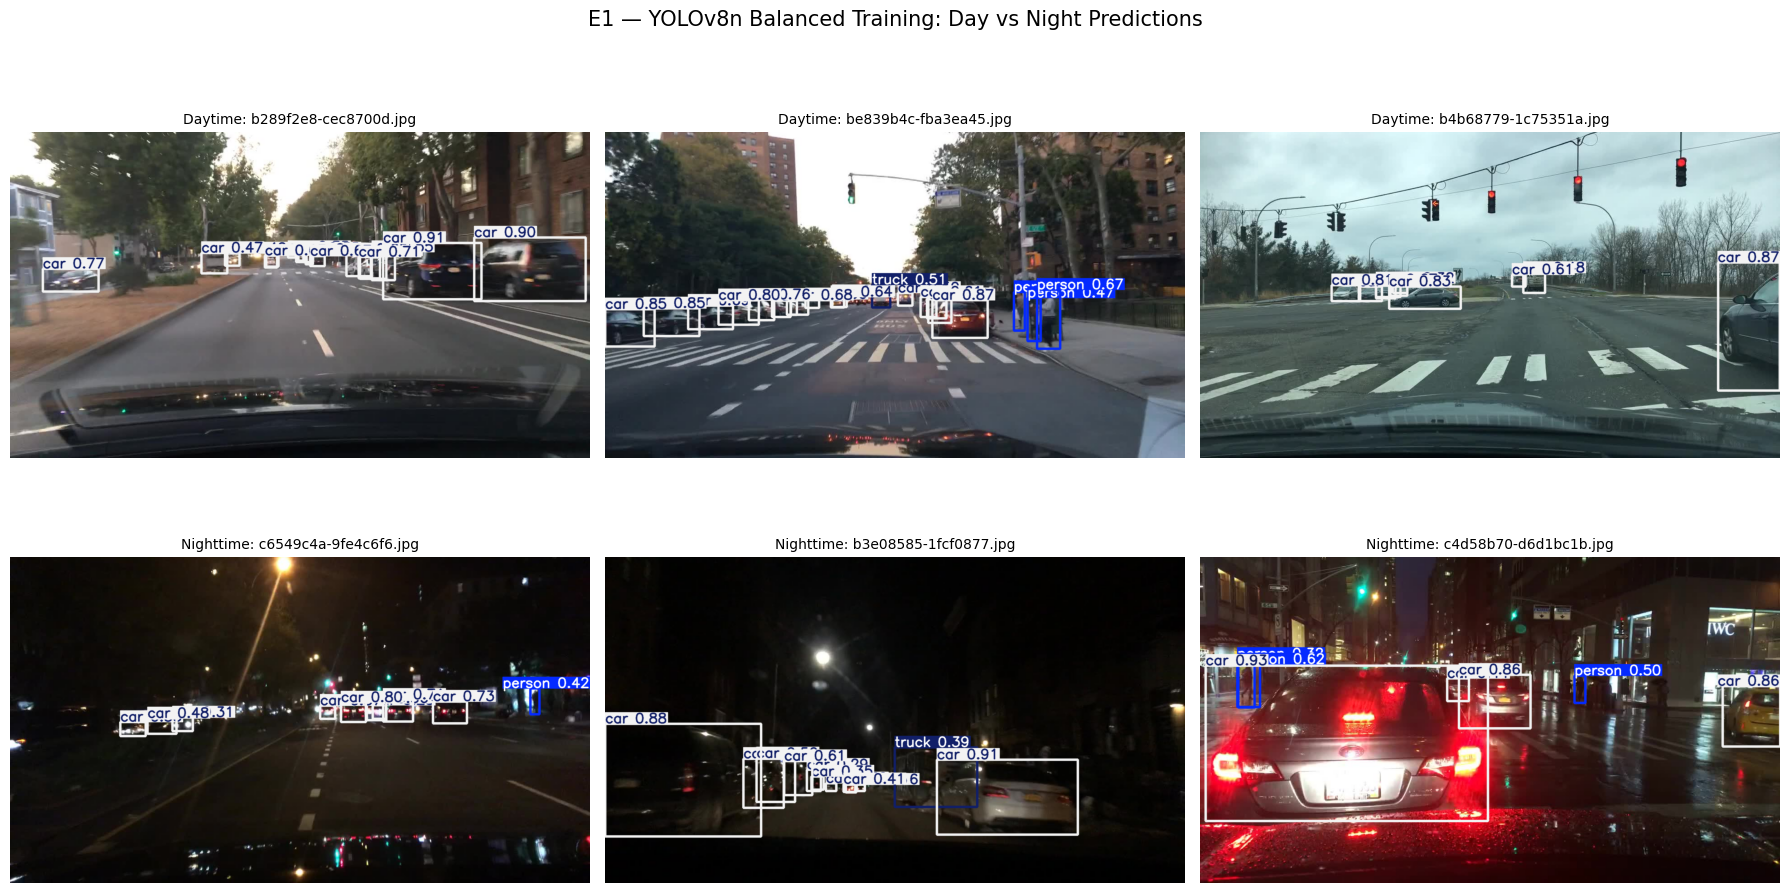

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import random

# Load the trained E1 model
e1_path = (
    Path(project_dir)
    / "experiment_results"
    / "E1_Balanced_Training"
    / "weights"
    / "best.pt"
)

assert e1_path.is_file(), f"Model not found: {e1_path}"

model_e1_vis = YOLO(str(e1_path))

# Existing validation images
val_dir = Path(project_dir) / "images" / "val"

# Select 3 daytime and 3 nighttime images
rng = random.Random(42)

day_samples = rng.sample(day_names, 3)
night_samples = rng.sample(night_names, 3)

samples = [
    ("Daytime", name) for name in day_samples
] + [
    ("Nighttime", name) for name in night_samples
]

# Display predictions
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for ax, (timeofday, filename) in zip(axes.flat, samples):

    image_path = val_dir / filename
    assert image_path.is_file(), f"Missing: {image_path}"

    results = model_e1_vis.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )

    # Draw predicted bounding boxes
    annotated = results[0].plot()

    # Convert BGR to RGB for Matplotlib
    annotated = cv2.cvtColor(
        annotated, cv2.COLOR_BGR2RGB
    )

    ax.imshow(annotated)
    ax.set_title(f"{timeofday}: {filename}", fontsize=10)
    ax.axis("off")

plt.suptitle(
    "E1 — YOLOv8n Balanced Training: Day vs Night Predictions",
    fontsize=15
)

plt.savefig(
    str(Path(project_dir) / "E1_day_night_predictions.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.tight_layout()
plt.show()

## Part E — Experiment E2: Night-only fine-tuning



**Step: Select E2 nighttime training images.**

In [ ]:
from pathlib import Path
import json
import yaml

project_dir = Path(project_dir)

# Existing dataset
train_manifest_path = project_dir / "train_manifest.json"

assert train_manifest_path.is_file(), (
    f"Missing training manifest: {train_manifest_path}"
)

with open(train_manifest_path, "r") as f:
    train_manifest = json.load(f)

# Select nighttime training images only
night_train_names = [
    item["name"]
    for item in train_manifest
    if item["timeofday"] == "night"
]

print("Nighttime training images:", len(night_train_names))

assert len(night_train_names) == 3500, (
    f"Expected 3500 nighttime images, found {len(night_train_names)}"
)

# Create E2 configuration directory
e2_dir = project_dir / "E2_Night_Only"
e2_dir.mkdir(parents=True, exist_ok=True)

# Create text file pointing to existing images
night_train_list = e2_dir / "night_train.txt"

train_image_dir = project_dir / "images" / "train"

with open(night_train_list, "w") as f:
    for name in night_train_names:
        image_path = train_image_dir / name

        assert image_path.is_file(), (
            f"Missing training image: {image_path}"
        )

        f.write(str(image_path.resolve()) + "\n")

print("Nighttime image list created:", night_train_list)

Nighttime training images: 3500
Nighttime image list created: /content/BDD100K_Project/E2_Night_Only/night_train.txt


**Step: Create E2 nighttime dataset configuration.**

In [ ]:
with open(yaml_path, "r") as f:
    e2_config = yaml.safe_load(f)

e2_config["path"] = str(project_dir.resolve())
e2_config["train"] = str(night_train_list.resolve())
e2_config["val"] = str(
    (project_dir / "images" / "val").resolve()
)

e2_yaml_path = e2_dir / "data_e2.yaml"

with open(e2_yaml_path, "w") as f:
    yaml.safe_dump(e2_config, f, sort_keys=False)

print("E2 dataset YAML:", e2_yaml_path)
print("Classes:", e2_config["names"])

E2 dataset YAML: /content/BDD100K_Project/E2_Night_Only/data_e2.yaml
Classes: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'bus', 4: 'truck'}


**Step: Train the E2 nighttime-only model.**

In [ ]:
from ultralytics import YOLO
import torch

device = 0 if torch.cuda.is_available() else "cpu"

# Start fresh from the same pretrained model used in E1
model_e2 = YOLO("yolov8n.pt")

results_e2 = model_e2.train(
    data=str(e2_yaml_path),
    epochs=20,
    imgsz=640,
    batch=8,
    device=device,
    workers=0,
    project=str(project_dir / "experiment_results"),
    name="E2_Night_Only_Training",
    seed=42,
    plots=True
)

print("E2 training completed!")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/BDD100K_Project/E2_Night_Only/data_e2.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=E2_Night_Only_Training, nbs=64, nms=No

### E4 — Save trained model checkpoints

### E4.1 — Copy E2 checkpoints to Google Drive

**Step: Save E2 checkpoints to Google Drive.**

In [ ]:
import shutil

e2_run_dir = Path(model_e2.trainer.save_dir)

e2_best = e2_run_dir / "weights" / "best.pt"
e2_last = e2_run_dir / "weights" / "last.pt"

drive_e2_dir = Path(
    "/content/drive/MyDrive/BDD100K_Project/saved_models/E2"
)

drive_e2_dir.mkdir(parents=True, exist_ok=True)

assert e2_best.is_file(), f"Missing checkpoint: {e2_best}"

shutil.copy2(e2_best, drive_e2_dir / "best.pt")

if e2_last.is_file():
    shutil.copy2(e2_last, drive_e2_dir / "last.pt")

print("E2 model saved:", drive_e2_dir)

E2 model saved: /content/drive/MyDrive/BDD100K_Project/saved_models/E2


### E5 — Evaluate E2 on both validation subsets

**Step: Evaluate E2 on day and night.**

In [ ]:
# Load the best E2 checkpoint
model_e2_best = YOLO(str(e2_best))

# Evaluate daytime validation images
e2_day_results = model_e2_best.val(
    data=str(day_yaml),
    imgsz=640,
    batch=8,
    device=device,
    workers=0,
    plots=False,
    verbose=False
)

# Evaluate nighttime validation images
e2_night_results = model_e2_best.val(
    data=str(night_yaml),
    imgsz=640,
    batch=8,
    device=device,
    workers=0,
    plots=False,
    verbose=False
)

print("E2 daytime and nighttime evaluation completed!")

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1321.5±496.1 MB/s, size: 71.0 KB)
val: Scanning /content/BDD100K_Project/labels/val... 750 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 750/750 855.4it/s 0.9s
val: New cache created: /content/BDD100K_Project/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 94/94 9.9it/s 9.5s
                   all        750      10305      0.462      0.325      0.321      0.187
Speed: 0.2ms preprocess, 4.2ms inference, 0.0ms loss, 1.0ms postprocess per image
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1323.0±434.4 MB/s, size: 38.2 KB)
val: Sca

### E6 — Summarize E2 detection metrics

**Step: Summarize E2 results.**

In [ ]:
import pandas as pd

e2_day_metrics = {
    "mAP50": e2_day_results.box.map50,
    "mAP50-95": e2_day_results.box.map,
    "precision": e2_day_results.box.mp,
    "recall": e2_day_results.box.mr
}

e2_night_metrics = {
    "mAP50": e2_night_results.box.map50,
    "mAP50-95": e2_night_results.box.map,
    "precision": e2_night_results.box.mp,
    "recall": e2_night_results.box.mr
}

comparison_e2 = pd.DataFrame({
    "day": e2_day_metrics,
    "night": e2_night_metrics
})

comparison_e2["gap"] = (
    comparison_e2["day"] - comparison_e2["night"]
)

print("\nE2 — Nighttime-Only Training: Day vs Night")
print(comparison_e2.round(4))


E2 — Nighttime-Only Training: Day vs Night
              day   night     gap
mAP50      0.3215  0.3948 -0.0733
mAP50-95   0.1874  0.2276 -0.0402
precision  0.4617  0.5271 -0.0655
recall     0.3249  0.3719 -0.0470


## Part F — Experiment E4: Day-only fine-tuning



**Step: Select E4 daytime training images.**

In [ ]:

from pathlib import Path
import json
import yaml

# Reuse existing project directory
project_dir = Path(project_dir)

train_manifest_path = project_dir / "train_manifest.json"

assert train_manifest_path.is_file(), (
    f"Missing training manifest: {train_manifest_path}"
)

with open(train_manifest_path, "r") as f:
    train_manifest = json.load(f)

# Select only daytime images
day_train_names = [
    item["name"]
    for item in train_manifest
    if item["timeofday"] == "daytime"
]

print("Daytime training images:", len(day_train_names))

assert len(day_train_names) == 3500, (
    f"Expected 3500 daytime images, found {len(day_train_names)}"
)

# Create E4 experiment directory
e4_dir = project_dir / "E4_Day_Only"
e4_dir.mkdir(parents=True, exist_ok=True)

train_image_dir = project_dir / "images" / "train"
day_train_list = e4_dir / "day_train.txt"

# Reference existing images without copying them
with open(day_train_list, "w") as f:
    for name in day_train_names:
        image_path = train_image_dir / name

        assert image_path.is_file(), (
            f"Missing training image: {image_path}"
        )

        f.write(str(image_path.resolve()) + "\n")

print("Daytime image list created:", day_train_list)


Daytime training images: 3500
Daytime image list created: /content/BDD100K_Project/E4_Day_Only/day_train.txt


### F2 — Configure daytime-only training data

**Step: Create E4 daytime dataset configuration.**

In [ ]:

# Load the original dataset configuration
yaml_path = project_dir / "data.yaml"

with open(yaml_path, "r") as f:
    e4_config = yaml.safe_load(f)

# Change training dataset to daytime-only
e4_config["path"] = str(project_dir.resolve())
e4_config["train"] = str(day_train_list.resolve())

# Keep the original validation dataset
e4_config["val"] = str(
    (project_dir / "images" / "val").resolve()
)

# Save E4 configuration
e4_yaml_path = e4_dir / "data_e4.yaml"

with open(e4_yaml_path, "w") as f:
    yaml.safe_dump(e4_config, f, sort_keys=False)

print("E4 dataset YAML:", e4_yaml_path)
print("Classes:", e4_config["names"])


E4 dataset YAML: /content/BDD100K_Project/E4_Day_Only/data_e4.yaml
Classes: {0: 'person', 1: 'bicycle', 2: 'car', 3: 'bus', 4: 'truck'}


### F3 — Fine-tune the day-only model

**Step: Train the E4 daytime-only model.**

In [ ]:

from ultralytics import YOLO
import torch

device = 0 if torch.cuda.is_available() else "cpu"

# Load fresh pretrained YOLOv8n
model_e4 = YOLO("yolov8n.pt")

# Train on daytime images only
results_e4 = model_e4.train(
    data=str(e4_yaml_path),
    epochs=20,
    imgsz=640,
    batch=32,
    device=device,
    workers=0,
    project=str(project_dir / "experiment_results"),
    name="E4_Day_Only_Training",
    seed=42,
    plots=True
)

print("E4 daytime-only training completed!")


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/BDD100K_Project/E4_Day_Only/data_e4.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=E4_Day_Only_Training-3, nbs=64, nms=Non

### F4 — Save trained E4 checkpoints

**Step: Save E4 checkpoints to Google Drive.**

In [ ]:

import shutil
from pathlib import Path

# Locate the E4 training run
e4_run_dir = Path(model_e4.trainer.save_dir)

e4_best = e4_run_dir / "weights" / "best.pt"
e4_last = e4_run_dir / "weights" / "last.pt"

# Google Drive storage
drive_e4_dir = Path(
    "/content/drive/MyDrive/BDD100K_Project/saved_models/E4"
)

drive_e4_dir.mkdir(parents=True, exist_ok=True)

assert e4_best.is_file(), f"Missing checkpoint: {e4_best}"

shutil.copy2(e4_best, drive_e4_dir / "best.pt")

if e4_last.is_file():
    shutil.copy2(e4_last, drive_e4_dir / "last.pt")

print("E4 model saved successfully!")
print("Location:", drive_e4_dir)


E4 model saved successfully!
Location: /content/drive/MyDrive/BDD100K_Project/saved_models/E4


**Step: Evaluate E4 on day and night.**

In [ ]:

# Load the best E2 model
model_e4_best = YOLO(str(e4_best))

# Evaluate on 750 daytime validation images
e4_day_results = model_e4_best.val(
    data=str(day_yaml),
    imgsz=640,
    batch=8,
    device=device,
    workers=0,
    plots=False,
    verbose=False
)

# Evaluate on 750 nighttime validation images
e4_night_results = model_e4_best.val(
    data=str(night_yaml),
    imgsz=640,
    batch=8,
    device=device,
    workers=0,
    plots=False,
    verbose=False
)

print("E4 daytime and nighttime evaluations completed!")


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2054.7±769.7 MB/s, size: 71.0 KB)
val: Scanning /content/BDD100K_Project/labels/val... 750 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 750/750 1.7Kit/s 0.4s
val: New cache created: /content/BDD100K_Project/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 94/94 8.6it/s 11.0s
                   all        750      10305      0.622      0.394      0.447      0.271
Speed: 0.3ms preprocess, 4.3ms inference, 0.0ms loss, 1.3ms postprocess per image
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 819.1±242.5 MB/s, size: 38.2 KB)
val: Scan

**Step: Summarize E4 results.**

In [ ]:

import pandas as pd

e4_day_metrics = {
    "mAP50": e4_day_results.box.map50,
    "mAP50-95": e4_day_results.box.map,
    "precision": e4_day_results.box.mp,
    "recall": e4_day_results.box.mr
}

e4_night_metrics = {
    "mAP50": e4_night_results.box.map50,
    "mAP50-95": e4_night_results.box.map,
    "precision": e4_night_results.box.mp,
    "recall": e4_night_results.box.mr
}

comparison_e4 = pd.DataFrame({
    "day": e4_day_metrics,
    "night": e4_night_metrics
})

# Gap = Day - Night
comparison_e4["gap"] = (
    comparison_e4["day"] - comparison_e4["night"]
)

print("\nE4 — Daytime-Only Training: Day vs Night")
print(comparison_e4.round(4))



E4 — Daytime-Only Training: Day vs Night
              day   night     gap
mAP50      0.4474  0.3743  0.0731
mAP50-95   0.2714  0.2157  0.0558
precision  0.6217  0.5257  0.0959
recall     0.3940  0.3494  0.0446
